<a href="https://colab.research.google.com/github/sonalimoorthy/PET-NN/blob/main/main_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC4002 NLP Project — Task 1 and Task 2

This notebook trains and compares two RNN models on the MASSIVE English dataset.

- **Task 1 — Intent classification:** predict one of the 60 intent labels for an utterance.
- **Task 2 — Slot filling:** predict a BIO slot label for each token in the utterance.

Both tasks use the same RNN encoder, with a separate output layer for each task.

## Experiments
1. **Unidirectional RNN:** reads the utterance from left to right.
2. **Bidirectional RNN:** reads the utterance from left to right and right to left.

The models use word embeddings, RNNs, softmax outputs and cross-entropy loss, following the SC4002 lecture material.

## 1. Imports and setup

The imports below are used for loading the data, building the neural networks, training them and checking their results.

In [1]:
import json
import random
import re
import tarfile
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


## 2. Load the MASSIVE English dataset

The notebook first checks whether the original JSONL file or a processed train/dev/test split is already available. If neither is found, it downloads the official MASSIVE archive.

In [2]:
DATA_URL = 'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz'

RAW_JSONL = Path('data/raw/en-US.jsonl')
RAW_ARCHIVE = Path('data/raw/amazon-massive-dataset-1.0.tar.gz')
PROCESSED_DIR = Path('data/processed')

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = list(root.rglob('en-US.jsonl'))
            if files:
                RAW_JSONL = files[0]
                print('Found dataset:', RAW_JSONL)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    for root in [Path('.'), Path('/kaggle/input')]:
        if root.exists():
            files = [p for p in root.rglob('*.tar.gz') if 'massive' in p.name.lower()]
            if files:
                RAW_ARCHIVE = files[0]
                print('Found archive:', RAW_ARCHIVE)
                break

if not RAW_JSONL.is_file() and not RAW_ARCHIVE.is_file():
    RAW_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading MASSIVE dataset...')
    urllib.request.urlretrieve(DATA_URL, RAW_ARCHIVE)


## 3. Tokenisation and reading the data

The tokeniser separates words and punctuation and converts tokens to lowercase. The same tokenisation is applied to the utterance and its slot annotations so that each input token has one slot label.

In [3]:
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)
SLOT_PATTERN = re.compile(r'\[([^:\]]+)\s*:\s*(.*?)\]')


def tokenize_utterance(text):
    return [word.lower() for word in TOKEN_PATTERN.findall(str(text))]


def read_jsonl(path):
    rows = []
    with Path(path).open('r', encoding='utf-8-sig') as file:
        for line in file:
            if line.strip():
                rows.append(json.loads(line))
    return rows


def read_archive(path):
    with tarfile.open(path, mode='r:gz') as archive:
        member = next(
            (item for item in archive if item.isfile() and item.name.endswith('/data/en-US.jsonl')),
            None
        )
        if member is None:
            raise FileNotFoundError('Could not find data/en-US.jsonl in the archive')

        stream = archive.extractfile(member)
        if stream is None:
            raise FileNotFoundError('Could not read the MASSIVE JSONL file')

        return [json.loads(line.decode('utf-8')) for line in stream if line.strip()]


def parse_annot_utt(annot_utt):
    words = []
    tags = []
    position = 0

    for match in SLOT_PATTERN.finditer(str(annot_utt)):
        outside = tokenize_utterance(annot_utt[position:match.start()])
        words.extend(outside)
        tags.extend(['O'] * len(outside))

        slot_name = match.group(1).strip()
        slot_words = tokenize_utterance(match.group(2).strip())

        if slot_words:
            words.extend(slot_words)
            tags.append('B-' + slot_name)
            tags.extend(['I-' + slot_name] * (len(slot_words) - 1))

        position = match.end()

    outside = tokenize_utterance(str(annot_utt)[position:])
    words.extend(outside)
    tags.extend(['O'] * len(outside))

    return words, tags


## 4. Prepare train, development and test data

The original MASSIVE partitions are kept. Slot labels are read from the annotated utterance when available. The code also accepts already processed rows that store their slot labels in `slots`, `slot_tags` or `slot_labels`.

In [4]:
def load_processed_splits(folder):
    result = {}
    for split in ['train', 'dev', 'test']:
        file_path = folder / (split + '.jsonl')
        if not file_path.is_file():
            return None
        result[split] = read_jsonl(file_path)
    return result


split_rows = load_processed_splits(PROCESSED_DIR)

if split_rows is not None:
    print('Using processed train/dev/test files.')
else:
    if RAW_JSONL.is_file():
        raw_rows = read_jsonl(RAW_JSONL)
    else:
        raw_rows = read_archive(RAW_ARCHIVE)

    split_rows = {'train': [], 'dev': [], 'test': []}

    for row in raw_rows:
        if row.get('locale') == 'en-US':
            split = row.get('partition')
            if split in split_rows:
                split_rows[split].append(row)

    print('Using original MASSIVE English records.')


data = {}

for split in ['train', 'dev', 'test']:
    cleaned = []

    for row in split_rows[split]:
        utterance = row.get('utt', row.get('utterance'))
        intent = row.get('intent')

        if utterance is None or intent is None:
            raise ValueError(f'{split} row is missing an utterance or intent.')

        if row.get('annot_utt') is not None:
            words, slots = parse_annot_utt(row['annot_utt'])
        else:
            words = row.get('tokens') or tokenize_utterance(utterance)
            slots = row.get('slots')
            if slots is None:
                slots = row.get('slot_tags')
            if slots is None:
                slots = row.get('slot_labels')

            if slots is None:
                raise ValueError(
                    f'{split} row has no slot labels. Check the preprocessing output format.'
                )

            slots = [str(tag) for tag in slots]

        if len(words) != len(slots):
            raise ValueError(
                f'{split} row has {len(words)} tokens but {len(slots)} slot labels. '
                'Check tokenisation and slot alignment.'
            )

        if len(words) == 0:
            words = ['<UNK>']
            slots = ['O']

        cleaned.append({
            'id': row.get('id', ''),
            'utt': str(utterance),
            'tokens': words,
            'intent': str(intent),
            'slots': slots
        })

    data[split] = cleaned

for split in ['train', 'dev', 'test']:
    print(f'{split}: {len(data[split]):,} utterances')

# The brief gives the exact size of each English split, so check that we
# really have all of them (and nothing got dropped while cleaning).
assert len(data['train']) == 11514, f"train has {len(data['train'])} rows, expected 11514"
assert len(data['dev']) == 2033, f"dev has {len(data['dev'])} rows, expected 2033"
assert len(data['test']) == 2974, f"test has {len(data['test'])} rows, expected 2974"
print('OK - split sizes match the brief (11,514 / 2,033 / 2,974)')

print('\nExample:')
print(data['train'][0])

Using original MASSIVE English records.
train: 11,514 utterances
dev: 2,033 utterances
test: 2,974 utterances
OK - split sizes match the brief (11,514 / 2,033 / 2,974)

Example:
{'id': '1', 'utt': 'wake me up at nine am on friday', 'tokens': ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'], 'intent': 'alarm_set', 'slots': ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']}


## 5. Convert intent and slot labels to IDs

The label mappings are created using the training set. The development and test sets are checked to make sure that they do not contain labels that were not seen during training.

In [5]:
intent_names = sorted({row['intent'] for row in data['train']})
intent2id = {name: index for index, name in enumerate(intent_names)}
id2intent = {index: name for name, index in intent2id.items()}
NUM_INTENTS = len(intent_names)

if NUM_INTENTS != 60:
    raise ValueError(f'Expected 60 intent labels, found {NUM_INTENTS}.')

slot_names = sorted({tag for row in data['train'] for tag in row['slots']})

# Add matching I- labels for slot types that appear with B- in training.
for tag in list(slot_names):
    if tag.startswith('B-'):
        inside_tag = 'I-' + tag[2:]
        if inside_tag not in slot_names:
            slot_names.append(inside_tag)

slot_names = sorted(set(slot_names))
slot2id = {name: index for index, name in enumerate(slot_names)}
id2slot = {index: name for name, index in slot2id.items()}
NUM_SLOTS = len(slot_names)

for split in ['dev', 'test']:
    new_intents = {row['intent'] for row in data[split]} - set(intent2id)
    new_slots = {tag for row in data[split] for tag in row['slots']} - set(slot2id)

    if new_intents:
        raise ValueError(f'Unknown intent labels in {split}: {sorted(new_intents)}')
    if new_slots:
        raise ValueError(f'Unknown slot labels in {split}: {sorted(new_slots)}')

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['intent_id'] = intent2id[row['intent']]
        row['slot_ids'] = [slot2id[tag] for tag in row['slots']]

print('Number of intent labels:', NUM_INTENTS)
print('Number of slot labels:', NUM_SLOTS)

intent_table = pd.DataFrame(
    [(i, name) for i, name in enumerate(intent_names[:10])],
    columns=['Intent ID', 'Intent name']
)
display(intent_table)


Number of intent labels: 60
Number of slot labels: 111


,Intent ID,Intent name
0,0,alarm_query
1,1,alarm_remove
2,2,alarm_set
3,3,audio_volume_down
4,4,audio_volume_mute
5,5,audio_volume_other
6,6,audio_volume_up
7,7,calendar_query
8,8,calendar_remove
9,9,calendar_set


## 6. Build the word vocabulary

Each word in the training data is assigned an ID. Words that only appear in development or test data are represented by the unknown token.

In [6]:
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
PAD_ID = 0
UNK_ID = 1

word_counts = Counter(
    word for row in data['train'] for word in row['tokens']
)

vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}

for word, count in word_counts.most_common():
    if word not in vocab:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)

for split in ['train', 'dev', 'test']:
    for row in data[split]:
        row['input_ids'] = [vocab.get(word, UNK_ID) for word in row['tokens']]
        row['length'] = len(row['input_ids'])

print('Vocabulary size:', VOCAB_SIZE)
print('Example tokens:', data['train'][0]['tokens'])
print('Example word IDs:', data['train'][0]['input_ids'])
print('Example slot tags:', data['train'][0]['slots'])


Vocabulary size: 5294
Example tokens: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
Example word IDs: [293, 4, 53, 22, 128, 47, 13, 140]
Example slot tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


## 7. Dataset and batches

Utterances have different lengths, so sequences in a batch are padded to the length of the longest utterance. Padding positions in the slot labels use `-100`, which is ignored by the slot loss.

In [7]:
IGNORE_INDEX = -100
BATCH_SIZE = 64


class MASSIVEDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        return (
            torch.tensor(row['input_ids'], dtype=torch.long),
            torch.tensor(row['intent_id'], dtype=torch.long),
            torch.tensor(row['slot_ids'], dtype=torch.long)
        )


def make_batch(batch):
    words, intents, slots = zip(*batch)

    lengths = torch.tensor([len(x) for x in words], dtype=torch.long)
    words = pad_sequence(words, batch_first=True, padding_value=PAD_ID)
    intents = torch.stack(intents)
    slots = pad_sequence(slots, batch_first=True, padding_value=IGNORE_INDEX)

    return words, lengths, intents, slots


train_loader = DataLoader(
    MASSIVEDataset(data['train']),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=make_batch
)

dev_loader = DataLoader(
    MASSIVEDataset(data['dev']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

print('Training batches:', len(train_loader))


Training batches: 180


## 8. Stage-1 model: a joint RNN for intent and slots

This is the Stage-1 model used for both experiments. Only the `bidirectional` flag changes between them.

**Architecture**
1. **Embedding layer.** `nn.Embedding(VOCAB_SIZE, 100)` turns each word ID into a 100-dimensional vector. `<PAD>` (ID 0) is the padding index, so it always stays a zero vector.
2. **RNN encoder.** A single-layer vanilla `nn.RNN` with a `tanh` activation and 96 hidden units, the same Elman RNN as in the lectures: $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$. The padded batch is packed first with `pack_padded_sequence`, so padding never changes the hidden state.
   - Unidirectional: each token output is 96-dimensional.
   - Bidirectional: a forward RNN and a backward RNN are concatenated, so each token output is 192-dimensional.
3. **Two output layers (heads).**
   - **Intent head:** a linear layer applied to the *final* hidden state of the sentence. In the bidirectional model, this is the last forward state concatenated with the last backward state.
   - **Slot head:** a linear layer applied to the hidden state at *every* token position.

**Inputs**
- `words`: a `(batch, max_len)` tensor of word IDs, padded with `PAD_ID`.
- `lengths`: a `(batch,)` tensor holding the real length of each utterance.

**Outputs**
- `intent_scores`: `(batch, 60)` logits, one score per intent.
- `slot_scores`: `(batch, max_len, NUM_SLOTS)` logits, one score vector per token.

The softmax is not a separate layer, because `nn.CrossEntropyLoss` applies log-softmax internally. At prediction time we just take the `argmax`.

**Loss**

$$L = \text{CE}(\text{intent}) + \text{CE}(\text{slots})$$

Both terms are cross-entropy losses. The slot loss uses `ignore_index=-100`, so padded positions add nothing to it. The two terms are simply added with equal weight.

**Optimiser:** plain mini-batch SGD with learning rate 0.05 (no momentum, no weight decay), batch size 64, for 15 epochs.

**Model selection:** after every epoch we evaluate on the dev set and compute a validation score:

$$\text{val score} = \tfrac{1}{2}(\text{intent accuracy} + \text{slot micro F1})$$

We use the average because the model is trained jointly, and selecting on only one of the two metrics would ignore the other task. Whenever the validation score beats the best so far, the checkpoint is saved to disk.

In [8]:
# Hyperparameters for the Stage-1 model
EMBEDDING_DIM = 100
HIDDEN_DIM = 96
EPOCHS = 15
LEARNING_RATE = 0.05


class JointRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_intents, num_slots, bidirectional=False):
        super().__init__()

        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=bidirectional,
            nonlinearity='tanh'
        )

        if bidirectional:
            output_size = hidden_dim * 2
        else:
            output_size = hidden_dim

        self.intent_layer = nn.Linear(output_size, num_intents)
        self.slot_layer = nn.Linear(output_size, num_slots)

    def forward(self, words, lengths):
        embedded = self.embedding(words)

        packed_words = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_outputs, last_hidden = self.rnn(packed_words)

        outputs, _ = pad_packed_sequence(
            packed_outputs,
            batch_first=True,
            total_length=words.size(1)
        )

        # Slot filling predicts one label for each token.
        slot_scores = self.slot_layer(outputs)

        # Intent classification uses the final hidden state.
        if self.bidirectional:
            forward_hidden = last_hidden[-2]
            backward_hidden = last_hidden[-1]
            sentence = torch.cat((forward_hidden, backward_hidden), dim=1)
        else:
            sentence = last_hidden[-1]

        intent_scores = self.intent_layer(sentence)

        return intent_scores, slot_scores

## 9. Number of parameters

The brief limits the model to **20M parameters**. We build each model once, just to count its parameters. Every parameter is trainable here, because nothing is frozen and no pretrained embeddings are used, so the total and trainable counts should be equal.

In [9]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


MAX_PARAMS = 20_000_000
param_counts = {}

for name, bi in [('Unidirectional RNN', False), ('Bidirectional RNN', True)]:
    temp_model = JointRNN(VOCAB_SIZE, EMBEDDING_DIM, HIDDEN_DIM,
                          NUM_INTENTS, NUM_SLOTS, bidirectional=bi)
    total, trainable = count_parameters(temp_model)
    param_counts[name] = (total, trainable)

    print(f'{name}: total = {total:,} | trainable = {trainable:,}')

    # breakdown per layer, just to see where most of the weights are
    for layer_name, layer in temp_model.named_children():
        n = sum(p.numel() for p in layer.parameters())
        print(f'    {layer_name:<13} {n:>10,}')

    assert total <= MAX_PARAMS, f'{name} has {total:,} parameters, which is over 20M!'

del temp_model
print('\nOK - both models are under the 20M parameter limit')

Unidirectional RNN: total = 564,995 | trainable = 564,995
    embedding        529,400
    rnn               19,008
    intent_layer       5,820
    slot_layer        10,767
Bidirectional RNN: total = 600,419 | trainable = 600,419
    embedding        529,400
    rnn               38,016
    intent_layer      11,580
    slot_layer        21,423

OK - both models are under the 20M parameter limit


## 10. Training and evaluation functions

Both tasks are trained together, and the loss is the sum of the intent and slot cross-entropy losses (see Section 8).

The same `get_scores` function is used for every evaluation in the notebook: during training, after reloading checkpoints, and on the test set. It returns:

- **Intent accuracy:** the percentage of utterances whose intent is predicted correctly.
- **Slot micro F1:** a predicted slot counts as correct only if its slot type *and* its full token span match the gold slot. True positives, false positives and false negatives are pooled over all utterances before F1 is calculated.
- **Loss:** the same joint loss as in training, averaged over the utterances. We use it as the validation loss.

For every epoch we record the training loss, the validation loss, the dev metrics and the time the epoch took. If the validation score (the average of intent accuracy and slot F1) is the best so far, the model is saved straight away. So the checkpoint on disk is always the **best epoch**, not the last one.

In [10]:
OUTPUT_DIR = Path('task1_task2_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)


def get_slot_spans(slot_tags):
    spans = set()
    start = None
    slot_type = None

    for index, tag in enumerate(slot_tags):
        if tag.startswith('B-'):
            if start is not None:
                spans.add((slot_type, start, index))

            start = index
            slot_type = tag[2:]

        elif tag.startswith('I-') and start is not None and tag[2:] == slot_type:
            continue

        else:
            if start is not None:
                spans.add((slot_type, start, index))
                start = None
                slot_type = None

            # Treat an I- tag without a matching open span as a new span.
            if tag.startswith('I-'):
                start = index
                slot_type = tag[2:]

    if start is not None:
        spans.add((slot_type, start, len(slot_tags)))

    return spans


def extract_slot_values(tokens, slot_tags):
    """
    Convert BIO tags into readable [slot_type: slot_span] values.

    Example:
        tokens = ['set', 'alarm', 'for', 'five', 'am']
        tags   = ['O', 'O', 'O', 'B-time', 'I-time']
        output = ['[time: five am]']
    """
    extracted = []
    for slot_type, start, end in sorted(
        get_slot_spans(slot_tags), key=lambda span: (span[1], span[2])
    ):
        span_text = ' '.join(tokens[start:end])
        extracted.append(f'[{slot_type}: {span_text}]')
    return extracted


def format_slot_values(tokens, slot_tags):
    """Format extracted slots as a single readable string."""
    values = extract_slot_values(tokens, slot_tags)
    return '; '.join(values) if values else 'No slots detected'


def get_scores(model, rows):
    loader = DataLoader(
        MASSIVEDataset(rows),
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=make_batch
    )

    model.eval()
    correct_intents = 0
    total_intents = 0
    true_spans = set()
    predicted_spans = set()

    # same loss functions as training, so the validation loss is comparable
    intent_loss_fn = nn.CrossEntropyLoss()
    slot_loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    total_loss = 0.0

    row_number = 0

    with torch.no_grad():
        for words, lengths, intent_labels, slot_labels in loader:
            words = words.to(DEVICE)
            intent_scores, slot_scores = model(words, lengths)

            batch_loss = intent_loss_fn(intent_scores, intent_labels.to(DEVICE)) + slot_loss_fn(
                slot_scores.reshape(-1, NUM_SLOTS),
                slot_labels.to(DEVICE).reshape(-1)
            )
            total_loss += batch_loss.item() * len(intent_labels)

            intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
            slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()
            slot_labels = slot_labels.tolist()

            for predicted_intent, predicted_slots, actual_intent, actual_slots, length in zip(
                intent_predictions,
                slot_predictions,
                intent_labels.tolist(),
                slot_labels,
                lengths.tolist()
            ):
                if predicted_intent == actual_intent:
                    correct_intents += 1
                total_intents += 1

                predicted_tags = [id2slot[tag] for tag in predicted_slots[:length]]
                actual_tags = [id2slot[tag] for tag in actual_slots[:length]]

                # Include the utterance number so spans from different
                # utterances are counted as separate examples.
                for slot_type, start, end in get_slot_spans(actual_tags):
                    true_spans.add((row_number, slot_type, start, end))

                for slot_type, start, end in get_slot_spans(predicted_tags):
                    predicted_spans.add((row_number, slot_type, start, end))

                row_number += 1

    true_positive = len(true_spans & predicted_spans)
    false_positive = len(predicted_spans - true_spans)
    false_negative = len(true_spans - predicted_spans)

    if (2 * true_positive + false_positive + false_negative) == 0:
        slot_micro_f1 = 0.0
    else:
        slot_micro_f1 = (
            100.0 * (2 * true_positive) /
            (2 * true_positive + false_positive + false_negative)
        )

    intent_accuracy = 100.0 * correct_intents / total_intents

    return {
        'intent_accuracy': intent_accuracy,
        'slot_micro_f1': slot_micro_f1,
        'loss': total_loss / total_intents
    }


def validation_score(scores):
    # we select checkpoints on the average of the two dev metrics
    return (scores['intent_accuracy'] + scores['slot_micro_f1']) / 2


def train_model(model_name, bidirectional, checkpoint_path):
    # re-seed so both experiments start from the same random state
    torch.manual_seed(SEED)

    model = JointRNN(
        vocab_size=VOCAB_SIZE,
        embedding_dim=EMBEDDING_DIM,
        hidden_dim=HIDDEN_DIM,
        num_intents=NUM_INTENTS,
        num_slots=NUM_SLOTS,
        bidirectional=bidirectional
    ).to(DEVICE)

    intent_loss = nn.CrossEntropyLoss()
    slot_loss = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimiser = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

    history = []
    best_score = -1.0
    best_epoch = 0
    run_start = time.time()

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.time()

        model.train()
        total_loss = 0.0
        total_rows = 0

        for words, lengths, intent_labels, slot_labels in train_loader:
            words = words.to(DEVICE)
            intent_labels = intent_labels.to(DEVICE)
            slot_labels = slot_labels.to(DEVICE)

            optimiser.zero_grad()

            intent_scores, slot_scores = model(words, lengths)

            loss_intent = intent_loss(intent_scores, intent_labels)
            loss_slots = slot_loss(
                slot_scores.reshape(-1, NUM_SLOTS),
                slot_labels.reshape(-1)
            )

            loss = loss_intent + loss_slots
            loss.backward()
            optimiser.step()

            total_loss += loss.item() * len(intent_labels)
            total_rows += len(intent_labels)

        train_loss = total_loss / total_rows

        # check on the dev set after every epoch
        dev_result = get_scores(model, data['dev'])
        dev_score = validation_score(dev_result)
        epoch_time = time.time() - epoch_start

        history.append({
            'epoch': epoch,
            'training_loss': train_loss,
            'validation_loss': dev_result['loss'],
            'dev_intent_accuracy': dev_result['intent_accuracy'],
            'dev_slot_micro_f1': dev_result['slot_micro_f1'],
            'dev_score': dev_score,
            'epoch_time_s': epoch_time
        })

        # save the model only when the validation score improves
        note = ''
        if dev_score > best_score:
            best_score = dev_score
            best_epoch = epoch
            torch.save({
                'model_state': model.state_dict(),
                'epoch': epoch,
                'val_score': dev_score,
                'vocab_size': VOCAB_SIZE,
                'embedding_dim': EMBEDDING_DIM,
                'hidden_dim': HIDDEN_DIM,
                'num_intents': NUM_INTENTS,
                'num_slots': NUM_SLOTS,
                'bidirectional': bidirectional,
                'vocab': vocab,
                'intent2id': intent2id,
                'slot2id': slot2id
            }, checkpoint_path)
            note = '  <- best so far, saved'

        print(
            f'{model_name} | Epoch {epoch:2d}/{EPOCHS} | '
            f'train loss {train_loss:.4f} | val loss {dev_result["loss"]:.4f} | '
            f'intent acc {dev_result["intent_accuracy"]:.2f}% | '
            f'slot F1 {dev_result["slot_micro_f1"]:.2f}% | '
            f'val score {dev_score:.2f} | {epoch_time:.1f}s{note}'
        )

    total_time = time.time() - run_start

    print(f'\nTotal training time: {total_time:.1f}s ({total_time / EPOCHS:.1f}s per epoch on average)')
    print(f'Best epoch: {best_epoch}')
    print(f'Best validation score (mean of intent acc and slot F1): {best_score:.2f}')
    print(f'Checkpoint file: {checkpoint_path}')

    best_info = {
        'best_epoch': best_epoch,
        'best_score': best_score,
        'checkpoint': checkpoint_path,
        'total_time': total_time
    }

    # note: the model returned here is from the LAST epoch,
    # the best one is on disk and gets reloaded later
    return model, pd.DataFrame(history), best_info


def load_checkpoint(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

    model = JointRNN(
        vocab_size=checkpoint['vocab_size'],
        embedding_dim=checkpoint['embedding_dim'],
        hidden_dim=checkpoint['hidden_dim'],
        num_intents=checkpoint['num_intents'],
        num_slots=checkpoint['num_slots'],
        bidirectional=checkpoint['bidirectional']
    ).to(DEVICE)

    model.load_state_dict(checkpoint['model_state'])
    model.eval()
    return model, checkpoint

## 11. Experiment 1: Unidirectional RNN

The unidirectional RNN reads the utterance from the first token to the last. Its final hidden state is used for intent classification, and its hidden state at each position is used for slot filling.

In [11]:
rnn_model, rnn_history, rnn_best = train_model(
    model_name='Unidirectional RNN',
    bidirectional=False,
    checkpoint_path=OUTPUT_DIR / 'best_unidirectional_rnn.pt'
)

Unidirectional RNN | Epoch  1/15 | train loss 5.5532 | val loss 4.8303 | intent acc 14.31% | slot F1 0.58% | val score 7.45 | 1.9s  <- best so far, saved
Unidirectional RNN | Epoch  2/15 | train loss 4.6015 | val loss 4.3796 | intent acc 23.32% | slot F1 12.21% | val score 17.76 | 1.8s  <- best so far, saved
Unidirectional RNN | Epoch  3/15 | train loss 4.1287 | val loss 3.9307 | intent acc 32.51% | slot F1 17.28% | val score 24.90 | 1.7s  <- best so far, saved
Unidirectional RNN | Epoch  4/15 | train loss 3.6956 | val loss 3.5463 | intent acc 39.35% | slot F1 19.83% | val score 29.59 | 1.7s  <- best so far, saved
Unidirectional RNN | Epoch  5/15 | train loss 3.3258 | val loss 3.2422 | intent acc 45.40% | slot F1 22.50% | val score 33.95 | 2.2s  <- best so far, saved
Unidirectional RNN | Epoch  6/15 | train loss 3.0406 | val loss 3.0196 | intent acc 49.98% | slot F1 24.01% | val score 36.99 | 1.8s  <- best so far, saved
Unidirectional RNN | Epoch  7/15 | train loss 2.8051 | val loss 2.

## 12. Experiment 2: Bidirectional RNN

The bidirectional RNN reads the utterance in both directions. The final forward and backward states are concatenated for intent classification, and the two directional outputs at each token position are used for slot filling.

In [12]:
birnn_model, birnn_history, birnn_best = train_model(
    model_name='Bidirectional RNN',
    bidirectional=True,
    checkpoint_path=OUTPUT_DIR / 'best_bidirectional_rnn.pt'
)

Bidirectional RNN | Epoch  1/15 | train loss 5.1651 | val loss 4.3506 | intent acc 27.89% | slot F1 7.16% | val score 17.52 | 2.7s  <- best so far, saved
Bidirectional RNN | Epoch  2/15 | train loss 4.0499 | val loss 3.7440 | intent acc 38.86% | slot F1 15.11% | val score 26.98 | 3.1s  <- best so far, saved
Bidirectional RNN | Epoch  3/15 | train loss 3.4899 | val loss 3.3138 | intent acc 45.55% | slot F1 21.58% | val score 33.56 | 2.9s  <- best so far, saved
Bidirectional RNN | Epoch  4/15 | train loss 3.0896 | val loss 2.9938 | intent acc 52.24% | slot F1 25.48% | val score 38.86 | 2.7s  <- best so far, saved
Bidirectional RNN | Epoch  5/15 | train loss 2.7805 | val loss 2.7513 | intent acc 57.21% | slot F1 28.60% | val score 42.91 | 3.1s  <- best so far, saved
Bidirectional RNN | Epoch  6/15 | train loss 2.5372 | val loss 2.5661 | intent acc 60.90% | slot F1 30.78% | val score 45.84 | 3.0s  <- best so far, saved
Bidirectional RNN | Epoch  7/15 | train loss 2.3368 | val loss 2.4270 |

## 13. Reload the best checkpoints and evaluate them

The models still in memory come from the *last* epoch, so we don't use them for evaluation. Instead we load each saved checkpoint from disk into a fresh `JointRNN`, then evaluate it on dev and test. There is no further training at this point.

As a sanity check, the dev validation score of the reloaded model should be the same as the best score printed during training. If it isn't, the wrong checkpoint was saved or loaded.

In [13]:
reloaded = {}

for name, best_info in [('Unidirectional RNN', rnn_best), ('Bidirectional RNN', birnn_best)]:
    model, checkpoint = load_checkpoint(best_info['checkpoint'])

    dev_result = get_scores(model, data['dev'])
    test_result = get_scores(model, data['test'])
    reloaded_score = validation_score(dev_result)

    print(f'{name}  (loaded {best_info["checkpoint"]}, saved at epoch {checkpoint["epoch"]})')
    print(f'  dev  -> intent acc {dev_result["intent_accuracy"]:.2f}% | slot F1 {dev_result["slot_micro_f1"]:.2f}% | val score {reloaded_score:.2f}')
    print(f'  test -> intent acc {test_result["intent_accuracy"]:.2f}% | slot F1 {test_result["slot_micro_f1"]:.2f}%')
    print(f'  best val score during training: {best_info["best_score"]:.4f} | after reload: {reloaded_score:.4f}')

    # the reloaded model has to give the same dev score as when it was saved
    assert abs(reloaded_score - best_info['best_score']) < 1e-4, \
        f'{name}: reloaded score {reloaded_score:.4f} does not match {best_info["best_score"]:.4f}'
    print('  OK - reloaded checkpoint matches the best epoch\n')

    reloaded[name] = {'model': model, 'dev': dev_result, 'test': test_result}

Unidirectional RNN  (loaded task1_task2_outputs/best_unidirectional_rnn.pt, saved at epoch 15)
  dev  -> intent acc 65.47% | slot F1 35.33% | val score 50.40
  test -> intent acc 64.06% | slot F1 34.45%
  best val score during training: 50.4017 | after reload: 50.4017
  OK - reloaded checkpoint matches the best epoch

Bidirectional RNN  (loaded task1_task2_outputs/best_bidirectional_rnn.pt, saved at epoch 15)
  dev  -> intent acc 70.98% | slot F1 43.31% | val score 57.15
  test -> intent acc 69.20% | slot F1 41.92%
  best val score during training: 57.1457 | after reload: 57.1457
  OK - reloaded checkpoint matches the best epoch



## 14. Compare the two experiments (report table)

The table below collects everything the report needs for each model: parameter counts, the number of epochs, the best epoch, training time, and the dev and test scores of the **reloaded** checkpoints.

The final model is chosen by **dev validation score only**, using the same criterion as checkpoint selection (the average of intent accuracy and slot F1). The test numbers are reported but never used to make a choice.

In [14]:
report_rows = []

for name, history, best_info in [
    ('Unidirectional RNN', rnn_history, rnn_best),
    ('Bidirectional RNN', birnn_history, birnn_best)
]:
    total, trainable = param_counts[name]
    dev_result = reloaded[name]['dev']
    test_result = reloaded[name]['test']

    report_rows.append({
        'Model': name,
        'Total params': total,
        'Trainable params': trainable,
        'Epochs trained': len(history),
        'Best epoch': best_info['best_epoch'],
        'Train time (s)': best_info['total_time'],
        'Avg time / epoch (s)': history['epoch_time_s'].mean(),
        'Dev intent acc (%)': dev_result['intent_accuracy'],
        'Dev slot F1 (%)': dev_result['slot_micro_f1'],
        'Dev val score': validation_score(dev_result),
        'Test intent acc (%)': test_result['intent_accuracy'],
        'Test slot F1 (%)': test_result['slot_micro_f1'],
        'Checkpoint': best_info['checkpoint'].name
    })

results = pd.DataFrame(report_rows)
display(results.round(2))

best_name = results.sort_values('Dev val score', ascending=False).iloc[0]['Model']

best_model = reloaded[best_name]['model']
if best_name == 'Unidirectional RNN':
    best_history = rnn_history
    best_info = rnn_best
else:
    best_history = birnn_history
    best_info = birnn_best

print('Selected model (highest dev validation score):', best_name)
print('Using checkpoint:', best_info['checkpoint'])

,Model,Total params,Trainable params,Epochs trained,Best epoch,Train time (s),Avg time / epoch (s),Dev intent acc (%),Dev slot F1 (%),Dev val score,Test intent acc (%),Test slot F1 (%),Checkpoint
0,Unidirectional RNN,564995,564995,15,15,28.57,1.90,65.47,35.33,50.40,64.06,34.45,best_unidirectional_rnn.pt
1,Bidirectional RNN,600419,600419,15,15,43.80,2.91,70.98,43.31,57.15,69.20,41.92,best_bidirectional_rnn.pt


Selected model (highest dev validation score): Bidirectional RNN
Using checkpoint: task1_task2_outputs/best_bidirectional_rnn.pt


## 15. Learning curves

The first row shows the training and validation loss of each model, with a dashed line at the epoch whose checkpoint was kept. The other plots show how dev intent accuracy and slot micro F1 changed from epoch to epoch.

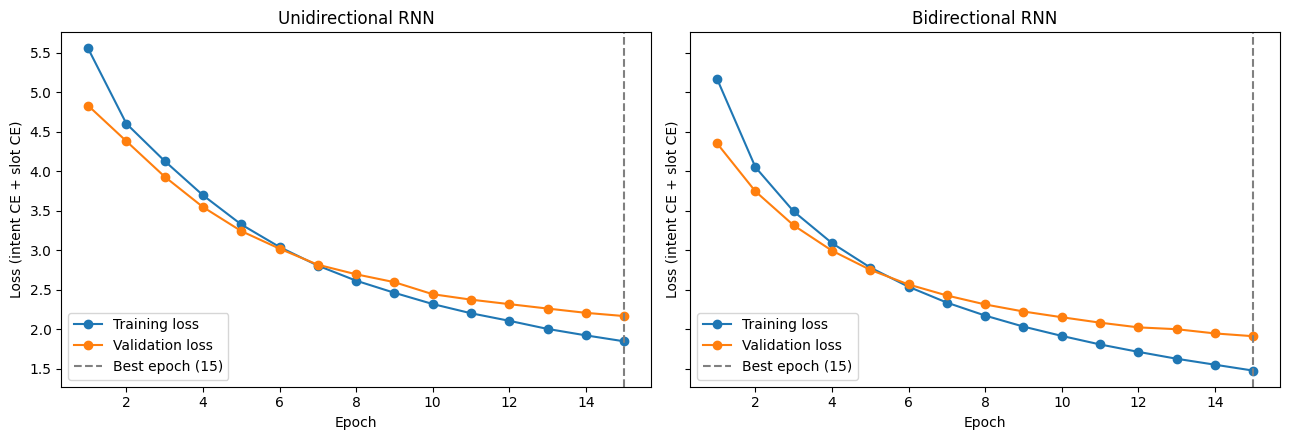

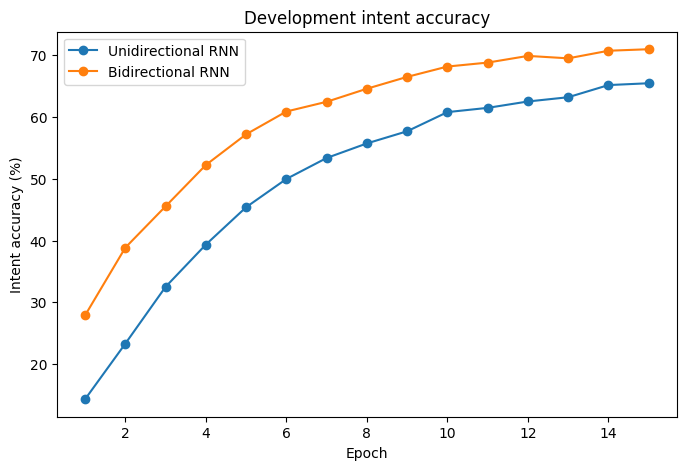

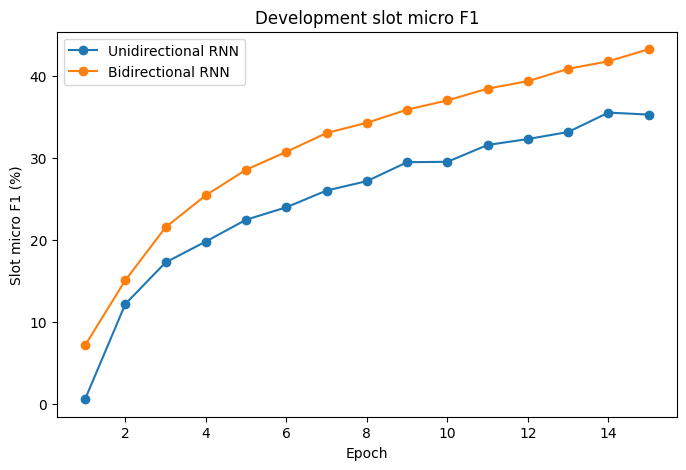

In [15]:
# training vs validation loss for each model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, (name, history, info) in zip(axes, [
    ('Unidirectional RNN', rnn_history, rnn_best),
    ('Bidirectional RNN', birnn_history, birnn_best)
]):
    ax.plot(history['epoch'], history['training_loss'], marker='o', label='Training loss')
    ax.plot(history['epoch'], history['validation_loss'], marker='o', label='Validation loss')
    ax.axvline(info['best_epoch'], color='grey', linestyle='--',
               label=f"Best epoch ({info['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (intent CE + slot CE)')
    ax.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_intent_accuracy'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_intent_accuracy'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Intent accuracy (%)')
plt.title('Development intent accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history['epoch'], rnn_history['dev_slot_micro_f1'], marker='o', label='Unidirectional RNN')
plt.plot(birnn_history['epoch'], birnn_history['dev_slot_micro_f1'], marker='o', label='Bidirectional RNN')
plt.xlabel('Epoch')
plt.ylabel('Slot micro F1 (%)')
plt.title('Development slot micro F1')
plt.legend()
plt.show()

## 16. Final test evaluation

This uses the selected model as it was **reloaded from its checkpoint** (Section 13), not the last-epoch model left in memory. Both metrics are percentages with two decimal places.

- Intent accuracy: the number of correct intent predictions divided by the number of utterances.
- Slot micro F1: exact matches of slot type and token span, pooled over all test utterances.

In [16]:
test_scores = get_scores(best_model, data['test'])

print('Selected model:', best_name)
print('Checkpoint:', best_info['checkpoint'], f"(epoch {best_info['best_epoch']})")
print(f'Test intent accuracy: {test_scores["intent_accuracy"]:.2f}%')
print(f'Test slot micro F1: {test_scores["slot_micro_f1"]:.2f}%')

Selected model: Bidirectional RNN
Checkpoint: task1_task2_outputs/best_bidirectional_rnn.pt (epoch 15)
Test intent accuracy: 69.20%
Test slot micro F1: 41.92%


## Readable slot extraction output

The model continues to train and predict using BIO tags (`B-time`, `I-time`, `O`, etc.), since these labels identify token boundaries. For the final output, consecutive BIO tags are decoded into readable slot-value pairs such as `[time: five am]`.

The test prediction CSV stores the readable values in `true_slots` and `predicted_slots`. The original token-level BIO sequences are also retained in `true_bio_tags` and `predicted_bio_tags` for debugging and evaluation.

## 17. Test predictions and output files

The output folder contains the test predictions of the selected model, the report table, the per-epoch history of both runs, the final test metrics, and the two best checkpoints (which were saved during training).

In [17]:
test_loader = DataLoader(
    MASSIVEDataset(data['test']),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=make_batch
)

prediction_rows = []
best_model.eval()

with torch.no_grad():
    for words, lengths, intent_labels, slot_labels in test_loader:
        words = words.to(DEVICE)
        intent_scores, slot_scores = best_model(words, lengths)

        intent_predictions = intent_scores.argmax(dim=1).cpu().tolist()
        slot_predictions = slot_scores.argmax(dim=2).cpu().tolist()

        for i, predicted_intent in enumerate(intent_predictions):
            length = lengths[i].item()
            predicted_slots = slot_predictions[i][:length]
            row_index = len(prediction_rows)
            original = data['test'][row_index]

            prediction_rows.append({
                'id': original['id'],
                'utterance': original['utt'],
                'true_intent': original['intent'],
                'predicted_intent': id2intent[predicted_intent],
                # Human-readable slot extraction: [slot_type: slot span]
                'true_slots': format_slot_values(
                    original['tokens'], original['slots']
                ),
                'predicted_slots': format_slot_values(
                    original['tokens'],
                    [id2slot[tag] for tag in predicted_slots]
                ),
                # Keep token-level BIO tags as optional diagnostic columns.
                'true_bio_tags': ' '.join(original['slots']),
                'predicted_bio_tags': ' '.join(
                    id2slot[tag] for tag in predicted_slots
                )
            })

pd.DataFrame(prediction_rows).to_csv(
    OUTPUT_DIR / 'test_predictions.csv',
    index=False
)

results.to_csv(OUTPUT_DIR / 'report_table.csv', index=False, float_format='%.2f')
rnn_history.to_csv(OUTPUT_DIR / 'history_unidirectional_rnn.csv', index=False)
birnn_history.to_csv(OUTPUT_DIR / 'history_bidirectional_rnn.csv', index=False)

pd.DataFrame([{
    'selected_model': best_name,
    'checkpoint': best_info['checkpoint'].name,
    'best_epoch': best_info['best_epoch'],
    'test_intent_accuracy': test_scores['intent_accuracy'],
    'test_slot_micro_f1': test_scores['slot_micro_f1']
}]).to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False, float_format='%.2f')

# no need to torch.save again here - the best checkpoints were already
# written during training (best_unidirectional_rnn.pt / best_bidirectional_rnn.pt)

print('Files saved in:', OUTPUT_DIR.resolve())

Files saved in: /content/task1_task2_outputs


## 18. Predict an intent and slots for a new utterance

This uses the same tokenisation and vocabulary as the training data, together with the selected model reloaded from its checkpoint. The model returns one intent, plus one slot label for each token.

Note that the official **slot micro F1** is the one pooled over the full dev or test set in Section 10. Nothing here changes it.

In [18]:
def predict_utterance(utterance):
    words = tokenize_utterance(utterance)

    if not words:
        words = [UNK_TOKEN]

    word_ids = [vocab.get(word, UNK_ID) for word in words]
    input_words = torch.tensor(
        [word_ids],
        dtype=torch.long,
        device=DEVICE
    )
    lengths = torch.tensor([len(word_ids)], dtype=torch.long)

    best_model.eval()

    with torch.no_grad():
        intent_scores, slot_scores = best_model(input_words, lengths)

        intent_id = int(intent_scores.argmax(dim=1).item())
        slot_ids = slot_scores.argmax(dim=2)[0].cpu().tolist()

    predicted_intent = id2intent[intent_id]
    predicted_slots = [
        id2slot[index] for index in slot_ids[:len(words)]
    ]

    extracted_slots = extract_slot_values(words, predicted_slots)

    result = {
        'utterance': utterance,
        'predicted_intent': predicted_intent,
        'tokens': words,
        # Readable output requested: [slot_type: slot span]
        'predicted_slots': extracted_slots,
        # BIO tags are retained for debugging/evaluation if needed.
        'predicted_bio_tags': predicted_slots
    }

    return result


# Predict intent and slots for a new utterance.
result = predict_utterance('Set an alarm for 7 am tomorrow')

print('Utterance:', result['utterance'])
print('Predicted intent:', result['predicted_intent'])
print('Tokens:', result['tokens'])
print('Extracted slots:', '; '.join(result['predicted_slots']) if result['predicted_slots'] else 'No slots detected')
print('BIO tags:', result['predicted_bio_tags'])



Utterance: Set an alarm for 7 am tomorrow
Predicted intent: alarm_set
Tokens: ['set', 'an', 'alarm', 'for', '7', 'am', 'tomorrow']
Extracted slots: [time: 7 am]; [date: tomorrow]
BIO tags: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'B-date']
